## chargement du profil des zones

On charge `agg_data/zones_profil.csv`. Le fichier a 29 colonnes, mais seules les **24 features** entrent dans le modèle : les 4 colonnes d'identification servent à interpréter les résultats, et `faible_activite` sert à filtrer.

On garde uniquement les **zones actives** (`faible_activite = 0`) : les zones avec moins d'une course par jour ont des moyennes trop instables pour être segmentées de manière fiable.

**Effet sur les données :** la table des zones actives est en mémoire, et la liste des 24 features est fixée.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
warnings.filterwarnings("ignore")

AGG_DIR = os.path.join(os.getcwd(), "agg_data")
ML_DIR = os.path.join(os.getcwd(), "ml_data")
os.makedirs(ML_DIR, exist_ok=True)

profil = pd.read_csv(os.path.join(AGG_DIR, "zones_profil.csv"))
IDENTIFIANTS = ["zone_id", "nom_zone", "arrondissement", "type_zone"]
FEATURES = [c for c in profil.columns if c not in IDENTIFIANTS + ["faible_activite"]]

actives = profil[profil["faible_activite"] == 0].reset_index(drop=True)
print("Colonnes du fichier :", profil.shape[1])
print("Features utilisées par le modèle :", len(FEATURES))
print("Zones au total :", len(profil), "| zones actives gardées pour le clustering :", len(actives))

Colonnes du fichier : 29
Features utilisées par le modèle : 24
Zones au total : 263 | zones actives gardées pour le clustering : 257


## préparation des données

K-Means calcule des distances : toutes les variables doivent être complètes et sur la même échelle.

1. **Imputation** : s'il reste des valeurs vides (par exemple l'attente VTC dans une zone sans VTC), on les remplace par la **médiane** de la variable. La médiane est robuste aux valeurs extrêmes.
2. **Transformation logarithmique** (`log1p`) sur les variables très asymétriques : `courses_par_jour`, `duree_moy_min`, `distance_moy`, `prix_moy`, `prix_par_mile`, `attente_moy_min`. Sans elle, quelques zones extrêmes (Midtown, les aéroports) écraseraient toutes les autres dans les distances.
3. **Écrêtage** de `croissance_2025` entre −0,9 et +2,0 : une zone presque vide en 2024 peut afficher une croissance énorme qui n'a pas de sens.
4. **Retrait des features constantes** : une variable qui a la même valeur partout n'apporte aucune information au clustering.
5. **Standardisation** (`StandardScaler`) : chaque variable est centrée (moyenne 0) et réduite (écart-type 1), pour qu'aucune ne domine les distances simplement à cause de son unité.

**Effet sur les données :** la matrice `X`, une ligne par zone active et une colonne par feature, toutes centrées et réduites.

In [2]:
X_brut = actives[FEATURES].copy()

print("Valeurs vides avant imputation :")
vides = X_brut.isna().sum()
display(vides[vides > 0].to_frame("nb_vides"))
X_brut = X_brut.fillna(X_brut.median())

A_LOG = ["courses_par_jour", "duree_moy_min", "distance_moy", "prix_moy", "prix_par_mile", "attente_moy_min"]
for c in A_LOG:
    X_brut[c] = np.log1p(X_brut[c])
X_brut["croissance_2025"] = X_brut["croissance_2025"].clip(-0.9, 2.0)

constantes = [c for c in FEATURES if X_brut[c].std() < 1e-9]
print("Features constantes retirées :", constantes)
FEATURES = [c for c in FEATURES if c not in constantes]
X_brut = X_brut[FEATURES]

scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X_brut), columns=FEATURES)

print("Forme de X :", X.shape)
display(X.describe().T[["mean", "std"]].round(2))

Valeurs vides avant imputation :


,nb_vides
part_especes,1
attente_moy_min,1
part_partage,1
part_pmr,1
part_chauffeur,1


Features constantes retirées : []
Forme de X : (257, 24)


,mean,std
courses_par_jour,-0.0,1.0
part_yellow,0.0,1.0
part_green,0.0,1.0
part_fhv,-0.0,1.0
part_vtc,0.0,1.0
part_weekend,-0.0,1.0
part_nuit,-0.0,1.0
part_matin,-0.0,1.0
part_journee,0.0,1.0
part_fin_aprem,0.0,1.0


## corrélations entre features

On calcule la matrice de corrélation et on liste les paires de variables fortement corrélées (|r| ≥ 0,7). Elle justifie l'ACP : quand plusieurs variables mesurent presque la même chose, elles pèsent plusieurs fois dans les distances de K-Means.

Certaines corrélations sont attendues par construction : les 4 parts de service font 1, les 5 tranches horaires aussi, et la durée, la distance et le prix évoluent ensemble.

**Effet sur les données :** aucun, c'est un diagnostic. On affiche la liste des paires et la carte des corrélations.

Paires de variables fortement corrélées (|r| >= 0.7) : 22


,variable_1,variable_2,correlation
3,part_yellow,taux_pourboire,0.95
1,part_yellow,part_fin_aprem,0.90
4,part_yellow,part_cbd,0.88
12,part_fin_aprem,taux_pourboire,0.85
19,taux_pourboire,part_cbd,0.83
6,part_vtc,taux_pourboire,-0.83
17,distance_moy,prix_moy,0.83
15,duree_moy_min,distance_moy,0.83
21,part_cbd,part_chauffeur,-0.81
16,duree_moy_min,prix_moy,0.81


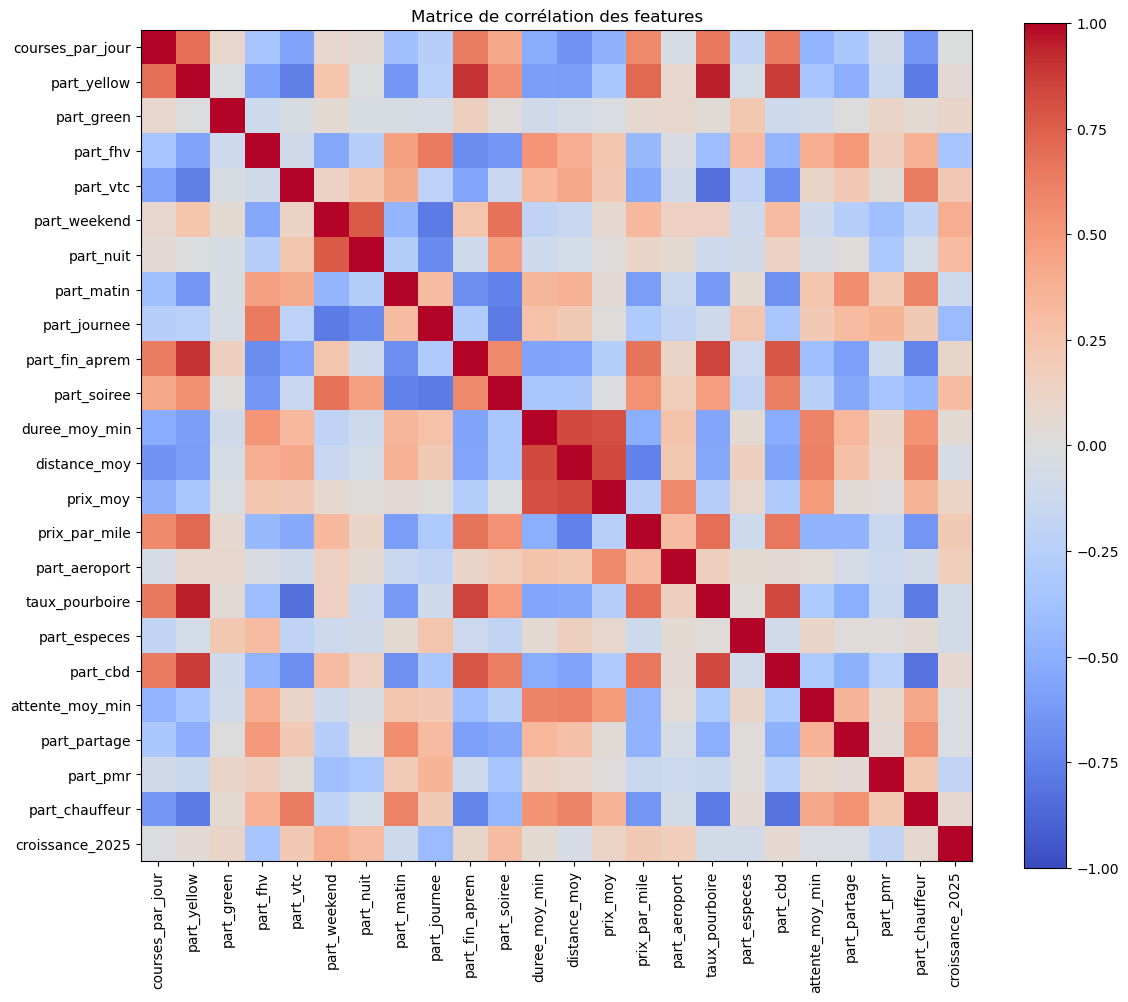

In [3]:
corr = X.corr()
paires = []
for i in range(len(FEATURES)):
    for j in range(i + 1, len(FEATURES)):
        r = corr.iloc[i, j]
        if abs(r) >= 0.7:
            paires.append((FEATURES[i], FEATURES[j], round(r, 2)))

paires = pd.DataFrame(paires, columns=["variable_1", "variable_2", "correlation"])
paires = paires.reindex(paires["correlation"].abs().sort_values(ascending=False).index)
print("Paires de variables fortement corrélées (|r| >= 0.7) :", len(paires))
display(paires)

plt.figure(figsize=(12, 10))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(FEATURES)), FEATURES, rotation=90)
plt.yticks(range(len(FEATURES)), FEATURES)
plt.title("Matrice de corrélation des features")
plt.tight_layout()
plt.show()

## ACP complète et choix du nombre de composantes

On applique une ACP avec **toutes** les composantes pour voir combien d'information (de variance) chacune résume. Deux critères classiques aident à choisir combien en garder :
- le **critère de Kaiser** : garder les composantes dont la valeur propre est supérieure à 1, c'est-à-dire celles qui résument plus d'information qu'une variable d'origine seule ;
- le **critère des 80 %** : garder le nombre de composantes nécessaire pour conserver au moins 80 % de la variance totale.

On affiche le tableau des valeurs propres, l'**éboulis** (scree plot) et la courbe de variance cumulée.

**Effet sur les données :** aucun, on décide du nombre de composantes à garder.

,composante,valeur_propre,variance_%,variance_cumulee_%
0,CP1,9.343,38.78,38.78
1,CP2,3.687,15.30,54.08
2,CP3,2.403,9.97,64.06
3,CP4,1.348,5.60,69.65
4,CP5,1.251,5.19,74.84
5,CP6,1.023,4.25,79.09
6,CP7,0.858,3.56,82.65
7,CP8,0.759,3.15,85.80
8,CP9,0.706,2.93,88.73
9,CP10,0.545,2.26,91.00


Critère de Kaiser (valeur propre > 1) : 6 composantes
Critère des 80 % de variance expliquée : 7 composantes


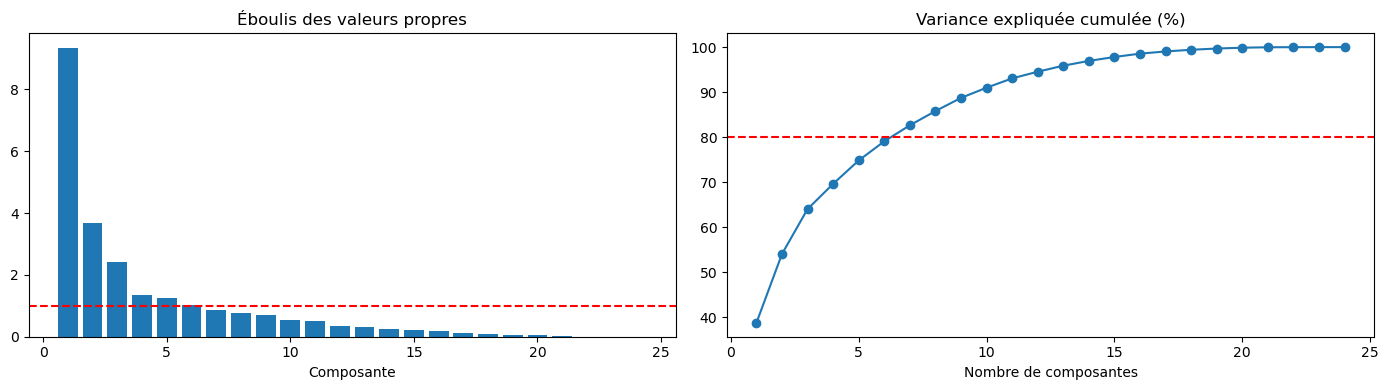

In [4]:
acp_complete = PCA().fit(X)
variance = acp_complete.explained_variance_ratio_
cumul = np.cumsum(variance)
valeurs_propres = acp_complete.explained_variance_

tableau = pd.DataFrame({
    "composante": ["CP" + str(i + 1) for i in range(len(variance))],
    "valeur_propre": valeurs_propres.round(3),
    "variance_%": (variance * 100).round(2),
    "variance_cumulee_%": (cumul * 100).round(2),
})
display(tableau)

N_KAISER = int((valeurs_propres > 1).sum())
N_80 = int(np.argmax(cumul >= 0.80) + 1)
print("Critère de Kaiser (valeur propre > 1) :", N_KAISER, "composantes")
print("Critère des 80 % de variance expliquée :", N_80, "composantes")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(range(1, len(variance) + 1), valeurs_propres)
axes[0].axhline(1, color="red", linestyle="--")
axes[0].set_title("Éboulis des valeurs propres")
axes[0].set_xlabel("Composante")
axes[1].plot(range(1, len(cumul) + 1), cumul * 100, marker="o")
axes[1].axhline(80, color="red", linestyle="--")
axes[1].set_title("Variance expliquée cumulée (%)")
axes[1].set_xlabel("Nombre de composantes")
plt.tight_layout()
plt.show()

## ACP réduite à 7 composantes

D'après l'éboulis et la variance cumulée :
- le **coude** apparaît après la 3e composante, mais 3 composantes ne gardent que ~64 % de l'information ;
- le **critère de Kaiser** donne 5 composantes sûres et une 6e à la limite (valeur propre ≈ 1), soit ~79 % ;
- le **critère des 80 %** est atteint à la **7e composante** (~82,5 %).

On garde donc **7 composantes** : c'est le plus petit nombre qui conserve plus de 80 % de la variance, et il laisse assez de dimensions pour les variables peu corrélées aux autres (`part_green`, `part_especes`, `croissance_2025`, `part_pmr`), qui sinon disparaîtraient.

**Effet sur les données :** la matrice `X_acp`, une ligne par zone active et 7 colonnes (CP1 à CP7), qui remplace les 24 features corrélées.

In [5]:
N_COMPOSANTES = 7

acp = PCA(n_components=N_COMPOSANTES)
X_acp = pd.DataFrame(acp.fit_transform(X), columns=["CP" + str(i + 1) for i in range(N_COMPOSANTES)])

print("Composantes gardées :", N_COMPOSANTES)
print("Variance conservée :", round(acp.explained_variance_ratio_.sum() * 100, 2), "%")
print("Forme de X_acp :", X_acp.shape)
display(pd.DataFrame({"valeur_propre": acp.explained_variance_.round(3),
                      "variance_%": (acp.explained_variance_ratio_ * 100).round(2)},
                     index=X_acp.columns))

Composantes gardées : 7
Variance conservée : 82.65 %
Forme de X_acp : (257, 7)


,valeur_propre,variance_%
CP1,9.343,38.78
CP2,3.687,15.30
CP3,2.403,9.97
CP4,1.348,5.60
CP5,1.251,5.19
CP6,1.023,4.25
CP7,0.858,3.56


##  interprétation des composantes

Pour donner un sens à chaque composante, on calcule trois indicateurs classiques de l'ACP :

- la **corrélation** entre chaque variable et chaque composante (entre −1 et 1) : son signe dit de quel côté de l'axe la variable tire, sa valeur dit à quel point elle est liée à l'axe ;
- le **cos²** (corrélation au carré) : la part de la variable expliquée par la composante. La somme des cos² sur les 7 composantes donne la **qualité de représentation** de chaque variable : proche de 1, la variable est bien conservée par l'ACP ; faible, elle est en partie perdue ;
- la **contribution** (en %) de chaque variable à la construction de chaque composante : les variables qui contribuent le plus donnent son nom à l'axe.

Pour chaque composante, on affiche les 5 variables qui contribuent le plus, avec leur signe.

**Effet sur les données :** aucun, c'est l'interprétation des axes.

In [6]:
correlations = pd.DataFrame(acp.components_.T * np.sqrt(acp.explained_variance_),
                            index=FEATURES, columns=X_acp.columns)

cos2 = correlations ** 2
qualite = cos2.sum(axis=1).sort_values()
contributions = (acp.components_.T ** 2) * 100
contributions = pd.DataFrame(contributions, index=FEATURES, columns=X_acp.columns)

print("Corrélations variables / composantes :")
display(correlations.round(2))

print("Qualité de représentation de chaque variable sur les", N_COMPOSANTES, "composantes (somme des cos²) :")
display(qualite.round(3).to_frame("cos2_total"))

for cp in X_acp.columns:
    top = contributions[cp].sort_values(ascending=False).head(5)
    signe = correlations.loc[top.index, cp].apply(lambda v: "+" if v > 0 else "-")
    print(cp, ":", ", ".join(signe[v] + v + " (" + str(round(top[v], 1)) + " %)" for v in top.index))

Corrélations variables / composantes :


,CP1,CP2,CP3,CP4,CP5,CP6,CP7
courses_par_jour,0.74,-0.24,-0.11,-0.04,-0.00,0.21,0.14
part_yellow,0.91,-0.19,0.21,-0.05,-0.04,0.00,0.17
part_green,0.05,-0.00,-0.01,0.72,0.46,-0.06,0.25
part_fhv,-0.67,-0.40,0.21,-0.31,0.28,0.11,-0.10
part_vtc,-0.58,0.56,-0.42,0.19,-0.24,-0.08,-0.16
part_weekend,0.43,0.78,-0.06,-0.10,0.17,-0.13,0.04
part_nuit,0.19,0.74,-0.22,-0.30,0.29,-0.04,0.04
part_matin,-0.74,-0.19,-0.29,0.03,0.02,0.25,0.00
part_journee,-0.46,-0.77,0.18,-0.01,-0.01,-0.01,-0.03
part_fin_aprem,0.89,-0.11,0.18,0.21,-0.15,-0.06,0.13


Qualité de représentation de chaque variable sur les 7 composantes (somme des cos²) :


,cos2_total
part_pmr,0.556
croissance_2025,0.573
courses_par_jour,0.692
part_matin,0.728
part_chauffeur,0.787
part_green,0.803
prix_par_mile,0.811
part_nuit,0.811
part_partage,0.831
attente_moy_min,0.838


CP1 : +part_yellow (8.9 %), +part_fin_aprem (8.4 %), +part_cbd (8.3 %), +taux_pourboire (7.8 %), -part_chauffeur (7.3 %)
CP2 : +part_weekend (16.4 %), -part_journee (16.3 %), +part_nuit (14.7 %), +part_vtc (8.5 %), +croissance_2025 (8.4 %)
CP3 : +prix_moy (23.4 %), +part_aeroport (16.9 %), +duree_moy_min (10.9 %), +distance_moy (9.2 %), -part_vtc (7.4 %)
CP4 : +part_green (38.6 %), +part_pmr (14.3 %), -part_fhv (6.9 %), -part_nuit (6.8 %), -attente_moy_min (4.7 %)
CP5 : +part_especes (39.5 %), +part_green (17.3 %), -part_pmr (7.2 %), +part_partage (6.9 %), +part_nuit (6.9 %)
CP6 : +part_aeroport (22.7 %), +part_partage (16.1 %), -part_especes (14.8 %), +croissance_2025 (11.0 %), +prix_par_mile (9.6 %)
CP7 : +attente_moy_min (31.6 %), +part_partage (13.3 %), -part_aeroport (9.2 %), +part_green (7.1 %), +croissance_2025 (7.0 %)


## cercles des corrélations

Le **cercle des corrélations** représente chaque variable par une flèche dans le plan de deux composantes :
- une flèche **longue**, proche du cercle, indique une variable bien représentée dans ce plan ;
- deux flèches dans la **même direction** indiquent des variables corrélées positivement ;
- deux flèches **opposées** indiquent des variables corrélées négativement ;
- deux flèches **perpendiculaires** indiquent des variables indépendantes.

On trace le premier plan (CP1 / CP2) et le deuxième (CP3 / CP4). Pour garder les graphiques lisibles, on n'affiche que les variables assez bien représentées dans le plan (corrélation totale ≥ 0,5).

**Effet sur les données :** aucun, ce sont des graphiques d'interprétation.

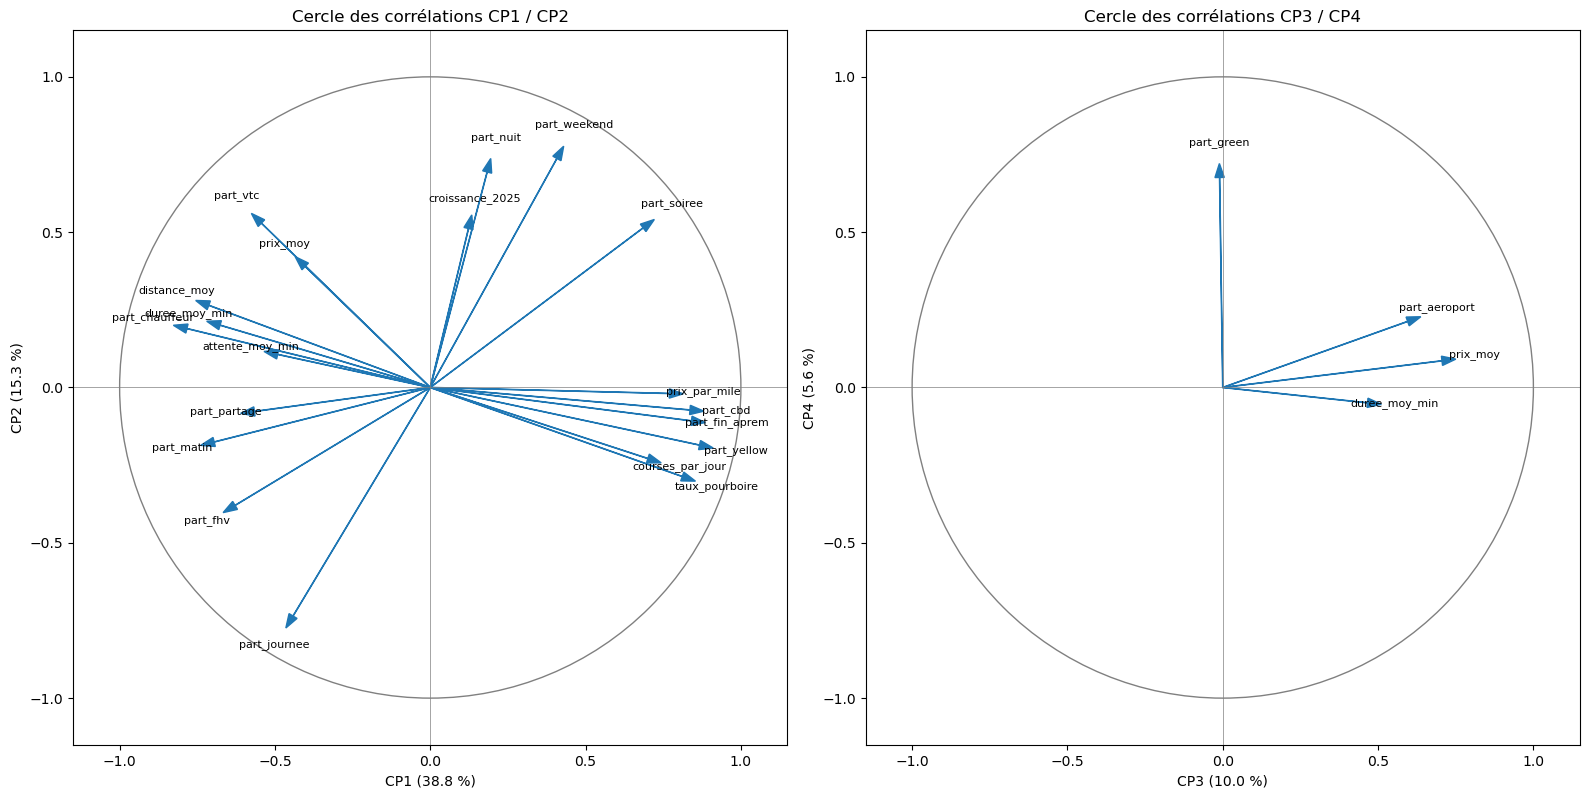

In [7]:
def cercle(cp_x, cp_y, ax):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(0, color="grey", linewidth=0.5)
    for var in FEATURES:
        x, y = correlations.loc[var, cp_x], correlations.loc[var, cp_y]
        if x ** 2 + y ** 2 >= 0.25:
            ax.arrow(0, 0, x, y, head_width=0.03, color="tab:blue", length_includes_head=True)
            ax.text(x * 1.08, y * 1.08, var, fontsize=8, ha="center")
    ax.set_xlim(-1.15, 1.15)
    ax.set_ylim(-1.15, 1.15)
    ax.set_aspect("equal")
    i, j = int(cp_x[2:]) - 1, int(cp_y[2:]) - 1
    ax.set_xlabel(cp_x + " (" + str(round(acp.explained_variance_ratio_[i] * 100, 1)) + " %)")
    ax.set_ylabel(cp_y + " (" + str(round(acp.explained_variance_ratio_[j] * 100, 1)) + " %)")
    ax.set_title("Cercle des corrélations " + cp_x + " / " + cp_y)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
cercle("CP1", "CP2", axes[0])
cercle("CP3", "CP4", axes[1])
plt.tight_layout()
plt.show()

## projection des zones sur le premier plan factoriel

Chaque zone active est placée selon ses coordonnées sur CP1 et CP2, avec une couleur par arrondissement (Manhattan, Brooklyn, Queens, Bronx, Staten Island). On affiche le nom des zones les plus extrêmes sur chaque axe pour aider à interpréter : les zones à droite et à gauche de CP1 illustrent ce que mesure le premier axe, celles en haut et en bas illustrent CP2.

Si des **nuages de points** séparés apparaissent déjà sur ce graphique, c'est un premier signe que des segments naturels existent, ce que K-Means devra confirmer.

**Effet sur les données :** aucun, c'est la visualisation des zones dans l'espace de l'ACP.

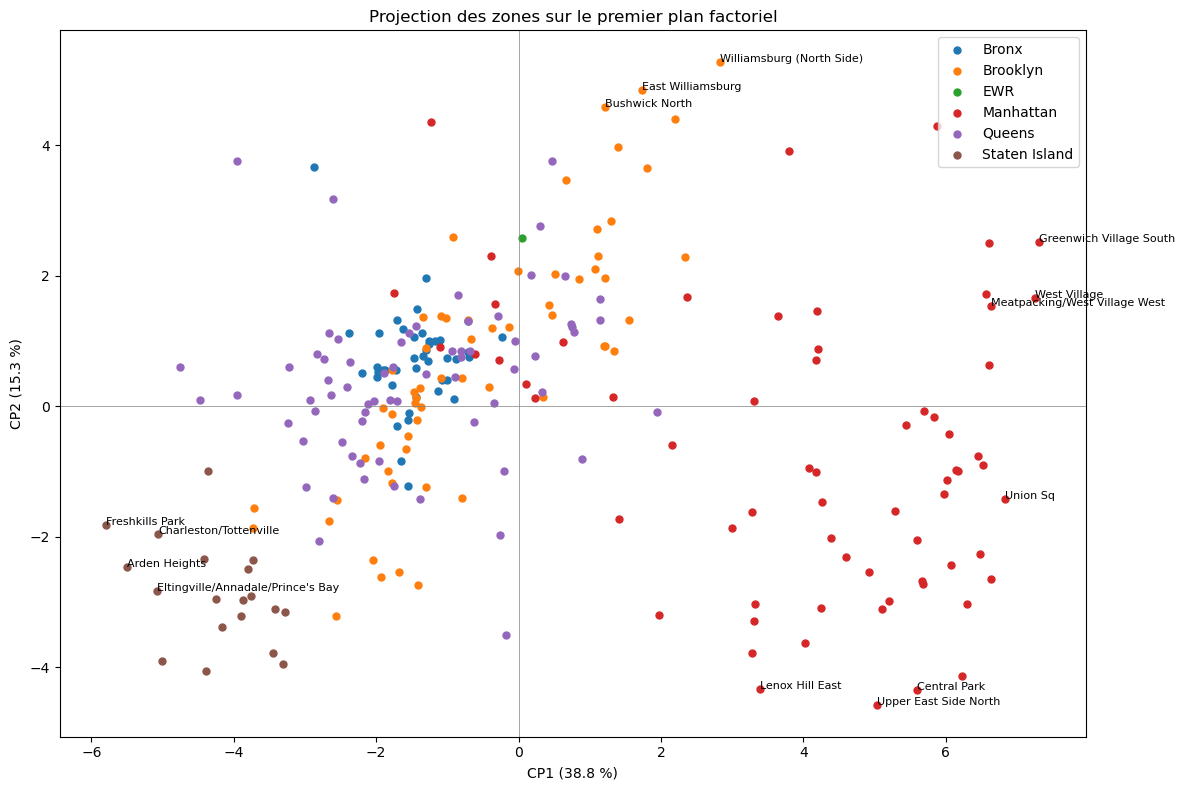

In [8]:
projection = pd.concat([actives[IDENTIFIANTS], X_acp], axis=1)

fig, ax = plt.subplots(figsize=(12, 8))
for arr in sorted(projection["arrondissement"].dropna().unique()):
    sous = projection[projection["arrondissement"] == arr]
    ax.scatter(sous["CP1"], sous["CP2"], s=25, label=arr)

extremes = pd.concat([projection.nlargest(4, "CP1"), projection.nsmallest(4, "CP1"),
                      projection.nlargest(3, "CP2"), projection.nsmallest(3, "CP2")]).drop_duplicates("zone_id")
for _, z in extremes.iterrows():
    ax.annotate(z["nom_zone"], (z["CP1"], z["CP2"]), fontsize=8)

ax.axhline(0, color="grey", linewidth=0.5)
ax.axvline(0, color="grey", linewidth=0.5)
ax.set_xlabel("CP1 (" + str(round(acp.explained_variance_ratio_[0] * 100, 1)) + " %)")
ax.set_ylabel("CP2 (" + str(round(acp.explained_variance_ratio_[1] * 100, 1)) + " %)")
ax.set_title("Projection des zones sur le premier plan factoriel")
ax.legend()
plt.tight_layout()
plt.show()

## métriques mathématiques AVANT l'ACP

On lance K-Means pour k = 2 à 10 sur les features standardisées `X`, et pour chaque k on calcule trois indices de qualité de la partition :

- **Score de silhouette** (entre −1 et 1, **plus haut = mieux**) : pour chaque zone, compare la distance moyenne aux zones de son propre groupe avec la distance moyenne aux zones du groupe voisin le plus proche. Une valeur proche de 1 signifie que la zone est bien dans son groupe ; proche de 0, qu'elle est à la frontière ; négative, qu'elle serait mieux dans un autre groupe.
- **Indice de Davies-Bouldin** (≥ 0, **plus bas = mieux**) : moyenne, sur tous les groupes, du rapport entre la dispersion à l'intérieur de deux groupes et la distance entre leurs centres. Il est faible quand les groupes sont compacts et éloignés les uns des autres.
- **Indice de Calinski-Harabasz** (≥ 0, **plus haut = mieux**) : rapport entre la dispersion **entre** les groupes et la dispersion **à l'intérieur** des groupes, corrigé par le nombre de groupes. Il est élevé quand les groupes sont bien séparés et homogènes.

`n_init=20` relance K-Means 20 fois avec des centres de départ différents et garde la meilleure solution ; `random_state=42` rend les résultats reproductibles.

**Effet sur les données :** aucun, on obtient un tableau de scores et le meilleur k selon chaque indice.

In [9]:
K_VALEURS = range(2, 11)

def evaluer_k(donnees, nom):
    lignes = []
    for k in K_VALEURS:
        km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(donnees)
        lignes.append({
            "k": k,
            "inertie": km.inertia_,
            "silhouette": silhouette_score(donnees, km.labels_),
            "davies_bouldin": davies_bouldin_score(donnees, km.labels_),
            "calinski_harabasz": calinski_harabasz_score(donnees, km.labels_),
        })
    res = pd.DataFrame(lignes)
    print(nom)
    print("  meilleur k selon la silhouette (max) :", int(res.loc[res["silhouette"].idxmax(), "k"]))
    print("  meilleur k selon Davies-Bouldin (min) :", int(res.loc[res["davies_bouldin"].idxmin(), "k"]))
    print("  meilleur k selon Calinski-Harabasz (max) :", int(res.loc[res["calinski_harabasz"].idxmax(), "k"]))
    return res

scores_avant = evaluer_k(X, "AVANT l'ACP (" + str(X.shape[1]) + " features)")
display(scores_avant.round(3))

AVANT l'ACP (24 features)
  meilleur k selon la silhouette (max) : 2
  meilleur k selon Davies-Bouldin (min) : 2
  meilleur k selon Calinski-Harabasz (max) : 2


,k,inertie,silhouette,davies_bouldin,calinski_harabasz
0,2,4304.261,0.374,1.097,110.415
1,3,3696.789,0.253,1.524,84.896
2,4,3266.059,0.265,1.636,74.931
3,5,2961.425,0.263,1.496,68.215
4,6,2756.226,0.260,1.476,62.140
5,7,2577.516,0.247,1.424,58.042
6,8,2421.667,0.258,1.222,55.029
7,9,2287.904,0.200,1.403,52.573
8,10,2174.972,0.183,1.391,50.385


## métriques mathématiques APRÈS l'ACP

On refait exactement le même test, avec les mêmes k et les mêmes réglages, mais sur les **7 composantes** `X_acp`.

- Si les deux espaces donnent le **même k**, la segmentation est **robuste** : elle ne dépend pas de la représentation choisie.
- Si la silhouette est **égale ou meilleure** après l'ACP, cela prouve que l'ACP a retiré de la redondance et du bruit sans détruire la structure des groupes.

**Effet sur les données :** aucun, on obtient le tableau de scores après l'ACP.

In [11]:
scores_apres = evaluer_k(X_acp, "APRÈS l'ACP (" + str(N_COMPOSANTES) + " composantes)")
display(scores_apres.round(3))

APRÈS l'ACP (7 composantes)
  meilleur k selon la silhouette (max) : 2
  meilleur k selon Davies-Bouldin (min) : 2
  meilleur k selon Calinski-Harabasz (max) : 2


,k,inertie,silhouette,davies_bouldin,calinski_harabasz
0,2,3236.997,0.434,0.939,146.599
1,3,2639.300,0.303,1.418,118.307
2,4,2214.588,0.325,1.328,109.801
3,5,1933.918,0.333,1.224,103.072
4,6,1751.555,0.309,1.234,95.908
5,7,1591.643,0.320,1.116,91.789
6,8,1451.420,0.310,1.039,89.369
7,9,1329.430,0.240,1.154,87.875
8,10,1261.653,0.232,1.176,83.450


##  comparaison graphique des trois métriques

On trace chaque métrique en fonction de k, avec une courbe avant l'ACP et une courbe après. Le bon k est celui où :
- la **silhouette** atteint un pic,
- **Davies-Bouldin** atteint un creux,
- **Calinski-Harabasz** reste élevé.

Les trois indices ne donnent pas toujours le même k : Calinski-Harabasz favorise souvent les petits k, et la silhouette peut rester proche entre deux valeurs. On cherche donc le k qui fait le **meilleur compromis**.

**Effet sur les données :** aucun, ce sont des graphiques de comparaison.

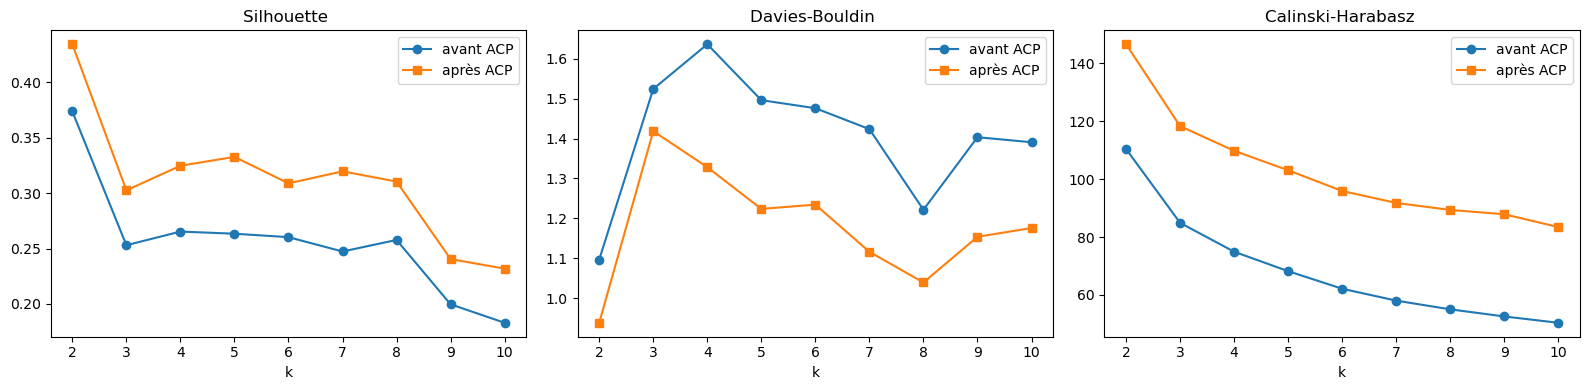

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, titre in zip(axes, ["silhouette", "davies_bouldin", "calinski_harabasz"],
                          ["Silhouette ", "Davies-Bouldin ", "Calinski-Harabasz "]):
    ax.plot(scores_avant["k"], scores_avant[col], marker="o", label="avant ACP")
    ax.plot(scores_apres["k"], scores_apres[col], marker="s", label="après ACP")
    ax.set_title(titre)
    ax.set_xlabel("k")
    ax.legend()
plt.tight_layout()
plt.show()

## méthode du coude avec KneeLocator

L'**inertie** (somme des distances au carré entre chaque zone et le centre de son groupe) baisse toujours quand k augmente. Au début, ajouter un groupe la fait chuter fortement ; à partir d'un certain k, le gain devient faible. Ce point de rupture est le **coude** : au-delà, on découpe des groupes qui existent déjà au lieu d'en découvrir de nouveaux.

On calcule l'inertie pour k = 1 à 10, avant et après l'ACP, et on détecte le coude automatiquement avec `KneeLocator` (bibliothèque `kneed`, courbe convexe et décroissante). Si `kneed` n'est pas installé ou ne trouve pas de coude, on utilise une méthode géométrique équivalente : le point de la courbe le plus éloigné de la droite qui relie ses deux extrémités.

**Effet sur les données :** aucun, on obtient le k du coude avant et après l'ACP, avec les deux courbes.

ERROR: Could not find a version that satisfies the requirement Kneed (from versions: none)
ERROR: No matching distribution found for Kneed


Note: you may need to restart the kernel to use updated packages.
kneed n'est pas installé : on utilise la méthode géométrique (point le plus éloigné de la droite).
Coude AVANT l'ACP : k = 3
Coude APRÈS l'ACP : k = 3


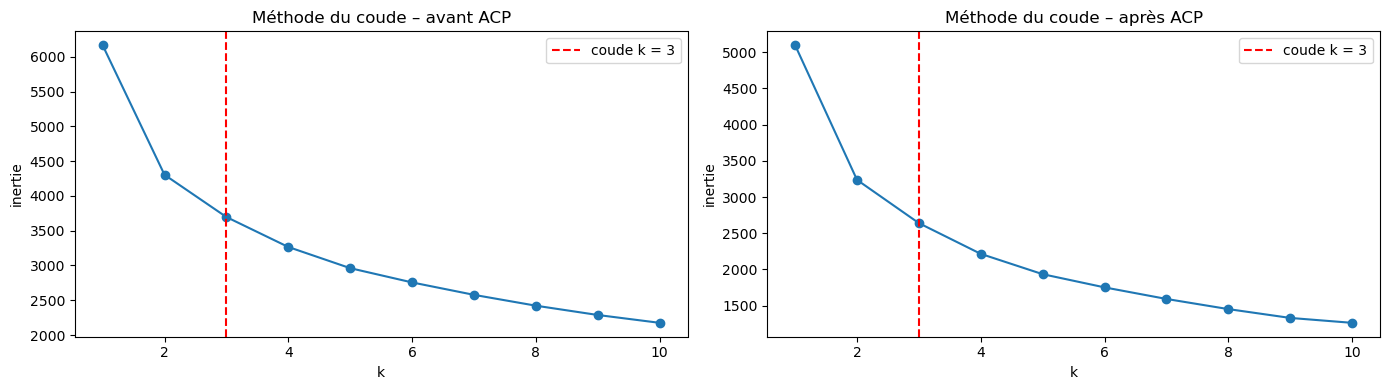

In [16]:
%pip install Kneed from KneeLocator

try:
    from kneed import KneeLocator
    KNEED = True
except ImportError:
    KNEED = False
    print("kneed n'est pas installé : on utilise la méthode géométrique (point le plus éloigné de la droite).")

def coude(ks, inerties):
    ks, inerties = np.array(list(ks)), np.array(inerties)
    if KNEED:
        kl = KneeLocator(ks, inerties, curve="convex", direction="decreasing")
        if kl.knee is not None:
            return int(kl.knee)
    x = (ks - ks.min()) / (ks.max() - ks.min())
    y = (inerties - inerties.min()) / (inerties.max() - inerties.min())
    distance = np.abs(x + y - 1) / np.sqrt(2)
    return int(ks[np.argmax(distance)])

K_COUDE = range(1, 11)
inerties_avant = [KMeans(n_clusters=k, n_init=20, random_state=42).fit(X).inertia_ for k in K_COUDE]
inerties_apres = [KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_acp).inertia_ for k in K_COUDE]
coude_avant = coude(K_COUDE, inerties_avant)
coude_apres = coude(K_COUDE, inerties_apres)
print("Coude AVANT l'ACP : k =", coude_avant)
print("Coude APRÈS l'ACP : k =", coude_apres)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, inerties, k_c, titre in [(axes[0], inerties_avant, coude_avant, "Méthode du coude – avant ACP"),
                                 (axes[1], inerties_apres, coude_apres, "Méthode du coude – après ACP")]:
    ax.plot(list(K_COUDE), inerties, marker="o")
    ax.axvline(k_c, color="red", linestyle="--", label="coude k = " + str(k_c))
    ax.set_title(titre)
    ax.set_xlabel("k")
    ax.set_ylabel("inertie")
    ax.legend()
plt.tight_layout()
plt.show()

## synthèse des critères et sauvegarde

On rassemble dans un seul tableau le meilleur k selon chacun des 4 critères (silhouette, Davies-Bouldin, Calinski-Harabasz, coude), avant et après l'ACP. Le k final se choisit en croisant :
- le **consensus** entre les critères ;
- la **stabilité** entre l'analyse avant et après l'ACP ;
- l'**interprétabilité** : des segments qu'on sait décrire et nommer, sans groupe minuscule de 2 ou 3 zones.

On sauvegarde dans `ml_data` tout ce dont les étapes suivantes (K-Means final, CAH, DBSCAN) auront besoin : la liste des zones actives, `X` standardisé, `X_acp` et les deux tableaux de scores.

**Effet sur les données :** aucun changement, les matrices et les scores sont gardés sur le disque.

In [17]:
def meilleurs(res, k_coude):
    return {
        "silhouette": int(res.loc[res["silhouette"].idxmax(), "k"]),
        "davies_bouldin": int(res.loc[res["davies_bouldin"].idxmin(), "k"]),
        "calinski_harabasz": int(res.loc[res["calinski_harabasz"].idxmax(), "k"]),
        "coude": k_coude,
    }

synthese = pd.DataFrame({"avant_ACP": meilleurs(scores_avant, coude_avant),
                         "apres_ACP": meilleurs(scores_apres, coude_apres)})
display(synthese)

actives[IDENTIFIANTS].to_csv(os.path.join(ML_DIR, "zones_actives.csv"), index=False)
X.to_csv(os.path.join(ML_DIR, "X_standardise.csv"), index=False)
X_acp.to_csv(os.path.join(ML_DIR, "X_acp.csv"), index=False)
scores_avant.to_csv(os.path.join(ML_DIR, "scores_k_avant_acp.csv"), index=False)
scores_apres.to_csv(os.path.join(ML_DIR, "scores_k_apres_acp.csv"), index=False)
print("Fichiers sauvegardés dans :", ML_DIR)

,avant_ACP,apres_ACP
silhouette,2,2
davies_bouldin,2,2
calinski_harabasz,2,2
coude,3,3


Fichiers sauvegardés dans : c:\Users\DELL\Desktop\esprit\ML\notebook_v0\Nootebook_vf\ml_data
